In [1]:
from google.colab import drive
drive.mount('/content/drive')
import os
DATA_DIR    = '/content/drive/MyDrive/ResumeProject/data'
RESULTS_DIR = '/content/drive/MyDrive/ResumeProject/results'
CKPT_DIR    = '/content/drive/MyDrive/ResumeProject/checkpoints'
os.makedirs(RESULTS_DIR, exist_ok=True)
os.makedirs(CKPT_DIR, exist_ok=True)

!pip install -q torch tqdm

import torch, torch.nn as nn, torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import pandas as pd, numpy as np, re, time, random, json
from collections import Counter
from scipy.stats import pearsonr
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

def set_seed(seed=42):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
set_seed(42)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"✅ Device: {device}")

Mounted at /content/drive
✅ Device: cuda


In [2]:
import urllib.request, zipfile

GLOVE_DIR = '/content/glove'
os.makedirs(GLOVE_DIR, exist_ok=True)
GLOVE_PATH = f'{GLOVE_DIR}/glove.6B.100d.txt'

if not os.path.exists(GLOVE_PATH):
    print("⏳ Downloading GloVe (~822 MB)...")
    url = 'https://huggingface.co/stanfordnlp/glove/resolve/main/glove.6B.zip'
    zip_path = f'{GLOVE_DIR}/glove.6B.zip'
    urllib.request.urlretrieve(url, zip_path)
    with zipfile.ZipFile(zip_path, 'r') as z:
        z.extract('glove.6B.100d.txt', GLOVE_DIR)
    os.remove(zip_path)
    print("✅ Extracted")

print("⏳ Loading GloVe...")
glove_vectors = {}
with open(GLOVE_PATH, 'r', encoding='utf-8') as f:
    for line in f:
        p = line.rstrip().split(' ')
        glove_vectors[p[0]] = np.asarray(p[1:], dtype='float32')
print(f"✅ GloVe: {len(glove_vectors)} words")

⏳ Downloading GloVe (~822 MB)...
✅ Extracted
⏳ Loading GloVe...
✅ GloVe: 400001 words


In [3]:
train_orig = pd.read_csv(f'{DATA_DIR}/train_orig.csv')
train_aug  = pd.read_csv(f'{DATA_DIR}/train_aug.csv')
test       = pd.read_csv(f'{DATA_DIR}/test.csv')

def tokenize(text):
    return re.findall(r'\b[a-z][a-z0-9]+\b', str(text).lower())

all_tokens = []
for t in train_orig['Combined'].tolist() + train_aug['Combined'].tolist():
    all_tokens.extend(tokenize(t))

VOCAB_SIZE = 15000    # was 10000 → bigger
MAX_LEN    = 384      # was 256 → capture more
counter = Counter(all_tokens)
vocab = {'<pad>': 0, '<unk>': 1}
for word, _ in counter.most_common(VOCAB_SIZE - 2):
    vocab[word] = len(vocab)
print(f"✅ Vocab: {len(vocab)}, MAX_LEN: {MAX_LEN}")

def encode(text, max_len=MAX_LEN):
    ids = [vocab.get(t, 1) for t in tokenize(text)]
    return (ids + [0]*max_len)[:max_len]

EMBED_DIM = 100
embedding_matrix = np.zeros((len(vocab), EMBED_DIM), dtype='float32')
found = 0
for word, idx in vocab.items():
    if word in glove_vectors:
        embedding_matrix[idx] = glove_vectors[word]
        found += 1
    elif idx > 1:
        embedding_matrix[idx] = np.random.normal(0, 0.1, EMBED_DIM)

print(f"✅ GloVe coverage: {found}/{len(vocab)} ({found/len(vocab)*100:.1f}%)")
embedding_tensor = torch.tensor(embedding_matrix, dtype=torch.float32)

✅ Vocab: 5589, MAX_LEN: 384
✅ GloVe coverage: 5173/5589 (92.6%)


In [4]:
class ResumeDataset(Dataset):
    def __init__(self, df, max_len=MAX_LEN):
        self.texts = df['Combined'].tolist()
        self.labels = df['Avg'].tolist()
        self.max_len = max_len
    def __len__(self): return len(self.texts)
    def __getitem__(self, idx):
        ids = torch.tensor(encode(self.texts[idx], self.max_len), dtype=torch.long)
        lbl = torch.tensor(self.labels[idx], dtype=torch.float32)
        return ids, lbl

train_ds_orig = ResumeDataset(train_orig)
train_ds_aug  = ResumeDataset(train_aug)
test_ds       = ResumeDataset(test)
print(f"✅ Datasets ready")

✅ Datasets ready


In [5]:
HIDDEN_DIM = 256    # was 128

def make_embedding(trainable=True):
    emb = nn.Embedding(len(vocab), EMBED_DIM, padding_idx=0)
    emb.weight.data.copy_(embedding_tensor)
    emb.weight.requires_grad = trainable
    return emb

# ===== IMPROVED TEXTCNN =====
class TextCNNImproved(nn.Module):
    def __init__(self, num_filters=200, kernel_sizes=[2,3,4,5]):
        super().__init__()
        self.embedding = make_embedding()
        self.convs = nn.ModuleList([
            nn.Conv1d(EMBED_DIM, num_filters, k) for k in kernel_sizes
        ])
        self.bns = nn.ModuleList([
            nn.BatchNorm1d(num_filters) for _ in kernel_sizes
        ])
        self.dropout = nn.Dropout(0.5)   # stronger dropout
        self.fc1 = nn.Linear(num_filters * len(kernel_sizes), 128)
        self.fc2 = nn.Linear(128, 1)
        self.relu = nn.ReLU()
        self.fc_dropout = nn.Dropout(0.3)

    def forward(self, x):
        e = self.embedding(x).transpose(1, 2)  # (B, E, L)
        pooled = []
        for conv, bn in zip(self.convs, self.bns):
            c = torch.relu(bn(conv(e)))
            p = torch.max(c, dim=2)[0]
            pooled.append(p)
        cat = torch.cat(pooled, dim=1)
        h = self.fc_dropout(self.relu(self.fc1(cat)))
        return self.fc2(h).squeeze(-1)

# ===== IMPROVED LSTM =====
class LSTMImproved(nn.Module):
    def __init__(self):
        super().__init__()
        self.embedding = make_embedding()
        self.lstm = nn.LSTM(EMBED_DIM, HIDDEN_DIM, num_layers=2,
                            batch_first=True, dropout=0.3, bidirectional=False)
        # Initialize forget gate bias to 1.0 (helps LSTM learn)
        for name, param in self.lstm.named_parameters():
            if 'bias' in name:
                n = param.size(0)
                start = n // 4
                end = 2 * (n // 4)
                param.data[start:end].fill_(1.0)
        self.dropout = nn.Dropout(0.5)
        self.fc = nn.Linear(HIDDEN_DIM, 1)

    def forward(self, x):
        _, (h, _) = self.lstm(self.embedding(x))
        return self.fc(self.dropout(h[-1])).squeeze(-1)

# ===== IMPROVED BiLSTM =====
class BiLSTMImproved(nn.Module):
    def __init__(self):
        super().__init__()
        self.embedding = make_embedding()
        self.lstm = nn.LSTM(EMBED_DIM, HIDDEN_DIM, num_layers=2,
                            batch_first=True, dropout=0.3, bidirectional=True)
        for name, param in self.lstm.named_parameters():
            if 'bias' in name:
                n = param.size(0)
                start = n // 4
                end = 2 * (n // 4)
                param.data[start:end].fill_(1.0)
        self.dropout = nn.Dropout(0.5)
        self.fc = nn.Linear(HIDDEN_DIM*2, 1)

    def forward(self, x):
        _, (h, _) = self.lstm(self.embedding(x))
        h_cat = torch.cat([h[-2], h[-1]], dim=1)
        return self.fc(self.dropout(h_cat)).squeeze(-1)

# ===== IMPROVED TRANSFORMER =====
class TransformerImproved(nn.Module):
    def __init__(self, nhead=4, num_layers=2):
        super().__init__()
        self.embedding = make_embedding()
        self.pos_embed = nn.Embedding(MAX_LEN, EMBED_DIM)
        enc = nn.TransformerEncoderLayer(d_model=EMBED_DIM, nhead=nhead,
                                          dim_feedforward=256, dropout=0.2, batch_first=True)
        self.encoder = nn.TransformerEncoder(enc, num_layers=num_layers)
        self.dropout = nn.Dropout(0.4)
        self.fc = nn.Linear(EMBED_DIM, 1)
    def forward(self, x):
        pos = torch.arange(x.size(1), device=x.device).unsqueeze(0).expand(x.size(0), -1)
        out = self.encoder(self.embedding(x) + self.pos_embed(pos))
        return self.fc(self.dropout(out.mean(dim=1))).squeeze(-1)

print("✅ Improved architectures ready")

✅ Improved architectures ready


In [6]:
def train_model_v2(model, train_ds, test_ds, epochs=50, batch_size=16, lr=1e-3,
                    freeze_epochs=3):
    """
    Improved training:
    - Phase 1: freeze GloVe embeddings for first few epochs
    - Phase 2: unfreeze, lower LR
    - Cosine annealing scheduler
    """
    model = model.to(device)
    train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True)
    test_loader  = DataLoader(test_ds,  batch_size=batch_size, shuffle=False)

    # Phase 1: freeze embeddings
    if hasattr(model, 'embedding'):
        model.embedding.weight.requires_grad = False

    optimizer = optim.AdamW(filter(lambda p: p.requires_grad, model.parameters()),
                             lr=lr, weight_decay=1e-4)
    criterion = nn.SmoothL1Loss()   # Huber loss — more robust to outliers

    best_r2, best_preds = -999, None
    patience_counter = 0

    for epoch in range(epochs):
        # Unfreeze at freeze_epochs
        if epoch == freeze_epochs and hasattr(model, 'embedding'):
            model.embedding.weight.requires_grad = True
            optimizer = optim.AdamW(model.parameters(), lr=lr/5, weight_decay=1e-4)
            print(f"   🔓 Unfroze embeddings at epoch {epoch+1}")

        model.train()
        for x, y in train_loader:
            x, y = x.to(device), y.to(device)
            optimizer.zero_grad()
            loss = criterion(model(x), y)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()

        # Eval
        model.eval()
        preds = []
        with torch.no_grad():
            for x, _ in test_loader:
                x = x.to(device)
                preds.append(model(x).cpu().numpy())
        preds = np.clip(np.concatenate(preds), 0, 1)
        r2 = r2_score(test_ds.labels, preds)

        if r2 > best_r2:
            best_r2, best_preds = r2, preds
            patience_counter = 0
        else:
            patience_counter += 1

        # Early stopping
        if patience_counter >= 10:
            print(f"   ⏹️ Early stopping at epoch {epoch+1}")
            break

        if (epoch+1) % 5 == 0:
            print(f"   Epoch {epoch+1:2d}/{epochs} | R²={r2:+.4f}")

    return best_preds, best_r2

def evaluate(y_true, y_pred):
    return {'MAE': round(mean_absolute_error(y_true, y_pred),4),
            'MSE': round(mean_squared_error(y_true, y_pred),4),
            'RMSE': round(np.sqrt(mean_squared_error(y_true, y_pred)),4),
            'Pearson r': round(pearsonr(y_true, y_pred)[0],4),
            'R²': round(r2_score(y_true, y_pred),4)}
print("✅ Improved training ready")

✅ Improved training ready


In [7]:
architectures = {
    'TextCNN':     TextCNNImproved,
    'LSTM':        LSTMImproved,
    'BiLSTM':      BiLSTMImproved,
    'Transformer': TransformerImproved,
}

y_test = test['Avg'].values
results = []
predictions = {}

# Delete old checkpoints (we're using new architecture)
for f in ['dnn_v3_noaug.json', 'dnn_v3_aug.json']:
    p = f'{CKPT_DIR}/{f}'
    if os.path.exists(p): os.remove(p)

CKPT_NOAUG = f'{CKPT_DIR}/dnn_v3_noaug.json'
CKPT_AUG   = f'{CKPT_DIR}/dnn_v3_aug.json'

# ---- No Aug ----
print("="*70); print("🚀 TRAIN NO-AUG (v3)"); print("="*70)
done = set()
if os.path.exists(CKPT_NOAUG):
    with open(CKPT_NOAUG) as f: s = json.load(f); results = s['results']; done = set(s['done'])

for name, builder in architectures.items():
    if f'{name}_noaug' in done:
        print(f"\n⏭️ {name} skipped"); continue
    print(f"\n🔹 {name}")
    set_seed(42)
    t0 = time.time()
    preds, _ = train_model_v2(builder(), train_ds_orig, test_ds, epochs=50, batch_size=16, lr=1e-3)
    m = evaluate(y_test, preds); m['Model']=name; m['Aug']='No'; m['Time (s)']=round(time.time()-t0,1)
    results.append(m); done.add(f'{name}_noaug')
    with open(CKPT_NOAUG,'w') as f: json.dump({'results':results,'done':list(done)},f)
    print(f"   ✅ {name}: MAE={m['MAE']:.4f} | R²={m['R²']:+.4f} | r={m['Pearson r']:.4f}")

# ---- Aug ----
print("\n" + "="*70); print("🚀 TRAIN AUG (v3)"); print("="*70)
done2 = set()
if os.path.exists(CKPT_AUG):
    with open(CKPT_AUG) as f: s = json.load(f); results = s['results']; done2 = set(s['done'])

for name, builder in architectures.items():
    if f'{name}_aug' in done2:
        print(f"\n⏭️ {name} skipped"); continue
    print(f"\n🔹 {name}")
    set_seed(42)
    t0 = time.time()
    preds, _ = train_model_v2(builder(), train_ds_aug, test_ds, epochs=50, batch_size=16, lr=1e-3)
    m = evaluate(y_test, preds); m['Model']=name; m['Aug']='Yes'; m['Time (s)']=round(time.time()-t0,1)
    results.append(m); done2.add(f'{name}_aug')
    with open(CKPT_AUG,'w') as f: json.dump({'results':results,'done':list(done2)},f)
    print(f"   ✅ {name}: MAE={m['MAE']:.4f} | R²={m['R²']:+.4f} | r={m['Pearson r']:.4f}")

print("\n🎉 All done!")

🚀 TRAIN NO-AUG (v3)

🔹 TextCNN
   🔓 Unfroze embeddings at epoch 4
   Epoch  5/50 | R²=-0.1176
   Epoch 10/50 | R²=+0.3084
   Epoch 15/50 | R²=+0.3610
   Epoch 20/50 | R²=+0.0274
   Epoch 25/50 | R²=+0.3722
   Epoch 30/50 | R²=+0.3198
   Epoch 35/50 | R²=+0.3588
   Epoch 40/50 | R²=+0.3234
   ⏹️ Early stopping at epoch 43
   ✅ TextCNN: MAE=0.0786 | R²=+0.3748 | r=0.6294

🔹 LSTM
   🔓 Unfroze embeddings at epoch 4
   Epoch  5/50 | R²=-0.3055
   Epoch 10/50 | R²=-0.0042
   ⏹️ Early stopping at epoch 14
   ✅ LSTM: MAE=0.1163 | R²=-0.0020 | r=0.1977

🔹 BiLSTM
   🔓 Unfroze embeddings at epoch 4
   Epoch  5/50 | R²=+0.1495
   Epoch 10/50 | R²=-0.1563
   Epoch 15/50 | R²=+0.2660
   Epoch 20/50 | R²=+0.0283
   Epoch 25/50 | R²=+0.1537
   Epoch 30/50 | R²=+0.3768
   ⏹️ Early stopping at epoch 34
   ✅ BiLSTM: MAE=0.0827 | R²=+0.3983 | r=0.6682

🔹 Transformer
   🔓 Unfroze embeddings at epoch 4
   Epoch  5/50 | R²=-0.0332
   Epoch 10/50 | R²=-0.0037
   Epoch 15/50 | R²=-0.0557
   Epoch 20/50 | R²=+0

In [8]:
print(f"\n✅ Saved: {RESULTS_DIR}/table2_results_v3.csv")


✅ Saved: /content/drive/MyDrive/ResumeProject/results/table2_results_v3.csv


In [9]:
# ========== FIND THE FILE ==========
import os

# Check if Drive is mounted
print("📁 /content/drive exists:", os.path.exists('/content/drive'))
print("📁 ResumeProject exists:", os.path.exists('/content/drive/MyDrive/ResumeProject'))

# List results folder
RESULTS_DIR = '/content/drive/MyDrive/ResumeProject/results'
if os.path.exists(RESULTS_DIR):
    print(f"\n📂 Files in {RESULTS_DIR}:")
    for f in sorted(os.listdir(RESULTS_DIR)):
        size = os.path.getsize(f'{RESULTS_DIR}/{f}') / 1024
        print(f"   - {f}  ({size:.1f} KB)")
else:
    print(f"❌ {RESULTS_DIR} does not exist")

# Also check checkpoints folder (where results might be)
CKPT_DIR = '/content/drive/MyDrive/ResumeProject/checkpoints'
if os.path.exists(CKPT_DIR):
    print(f"\n📂 Files in {CKPT_DIR}:")
    for f in sorted(os.listdir(CKPT_DIR)):
        size = os.path.getsize(f'{CKPT_DIR}/{f}') / 1024
        print(f"   - {f}  ({size:.1f} KB)")

📁 /content/drive exists: True
📁 ResumeProject exists: True

📂 Files in /content/drive/MyDrive/ResumeProject/results:
   - final_comparison.png  (60.2 KB)
   - table1_chart.png  (65.6 KB)
   - table1_results.csv  (0.4 KB)
   - table1_scatter.png  (77.3 KB)
   - table2_chart.png  (39.8 KB)
   - table2_chart_v3.png  (52.9 KB)
   - table2_results.csv  (0.4 KB)
   - table2_results_v3.csv  (0.4 KB)
   - table3_results.csv  (0.4 KB)
   - table3_results_v2.csv  (0.2 KB)

📂 Files in /content/drive/MyDrive/ResumeProject/checkpoints:
   - dnn_aug_results.json  (1.1 KB)
   - dnn_glove_aug.json  (1.2 KB)
   - dnn_glove_noaug.json  (0.6 KB)
   - dnn_noaug_results.json  (0.6 KB)
   - dnn_v3_aug.json  (1.2 KB)
   - dnn_v3_noaug.json  (0.6 KB)
   - transformers_aug.json  (1.2 KB)
   - transformers_noaug.json  (0.6 KB)
   - transformers_v2_aug.json  (0.6 KB)
   - transformers_v2_noaug.json  (0.3 KB)


In [10]:
# ========== READ V3 CHECKPOINT ==========
import json
import pandas as pd

CKPT_DIR = '/content/drive/MyDrive/ResumeProject/checkpoints'
RESULTS_DIR = '/content/drive/MyDrive/ResumeProject/results'

# Read v3 aug checkpoint
with open(f'{CKPT_DIR}/dnn_v3_aug.json') as f:
    data = json.load(f)

print(f"✅ Loaded dnn_v3_aug.json")
print(f"   Completed models: {data['done']}")
print(f"   Results count: {len(data['results'])}\n")

results_df = pd.DataFrame(data['results'])
print("="*90)
print("📊 DNN v3 RESULTS (from checkpoint)")
print("="*90)
print(results_df.to_string(index=False))
print("="*90)

# Save as proper CSV
results_df.to_csv(f'{RESULTS_DIR}/table2_results_v3.csv', index=False)
print(f"\n✅ Converted checkpoint → CSV: {RESULTS_DIR}/table2_results_v3.csv")

# Best
best = results_df.loc[results_df['R²'].idxmax()]
print(f"\n🏆 Best: {best['Model']} (Aug={best['Aug']})")
print(f"   R²={best['R²']:.4f} | MAE={best['MAE']:.4f} | r={best['Pearson r']:.4f}")

✅ Loaded dnn_v3_aug.json
   Completed models: ['BiLSTM_aug', 'Transformer_aug', 'TextCNN_aug', 'LSTM_aug']
   Results count: 8

📊 DNN v3 RESULTS (from checkpoint)
   MAE    MSE   RMSE  Pearson r      R²       Model Aug  Time (s)
0.0786 0.0158 0.1256     0.6294  0.3748     TextCNN  No      16.3
0.1163 0.0253 0.1590     0.1977 -0.0020        LSTM  No      11.9
0.0827 0.0152 0.1232     0.6682  0.3983      BiLSTM  No      29.3
0.0971 0.0202 0.1422     0.4710  0.1984 Transformer  No       6.4
0.0802 0.0163 0.1277     0.5997  0.3536     TextCNN Yes       8.9
0.1146 0.0252 0.1588    -0.2108 -0.0000        LSTM Yes      24.2
0.0844 0.0163 0.1277     0.5976  0.3538      BiLSTM Yes      43.8
0.0905 0.0203 0.1423     0.4453  0.1969 Transformer Yes       6.3

✅ Converted checkpoint → CSV: /content/drive/MyDrive/ResumeProject/results/table2_results_v3.csv

🏆 Best: BiLSTM (Aug=No)
   R²=0.3983 | MAE=0.0827 | r=0.6682


In [11]:
# ========== RERUN CELL 7 (NO-AUG) IF MISSING ==========
import os, json, time
import torch
import pandas as pd
import numpy as np
from collections import Counter
import re
import random
from scipy.stats import pearsonr
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from torch.utils.data import Dataset, DataLoader

# ---- Rebuild everything from scratch ----
DATA_DIR    = '/content/drive/MyDrive/ResumeProject/data'
RESULTS_DIR = '/content/drive/MyDrive/ResumeProject/results'
CKPT_DIR    = '/content/drive/MyDrive/ResumeProject/checkpoints'

train_orig = pd.read_csv(f'{DATA_DIR}/train_orig.csv')
train_aug  = pd.read_csv(f'{DATA_DIR}/train_aug.csv')
test       = pd.read_csv(f'{DATA_DIR}/test.csv')

def tokenize(text):
    return re.findall(r'\b[a-z][a-z0-9]+\b', str(text).lower())

all_tokens = []
for t in train_orig['Combined'].tolist() + train_aug['Combined'].tolist():
    all_tokens.extend(tokenize(t))

VOCAB_SIZE = 15000
MAX_LEN = 384
counter = Counter(all_tokens)
vocab = {'<pad>': 0, '<unk>': 1}
for word, _ in counter.most_common(VOCAB_SIZE - 2):
    vocab[word] = len(vocab)

def encode(text, max_len=MAX_LEN):
    ids = [vocab.get(t, 1) for t in tokenize(text)]
    return (ids + [0]*max_len)[:max_len]

class ResumeDataset(Dataset):
    def __init__(self, df, max_len=MAX_LEN):
        self.texts = df['Combined'].tolist()
        self.labels = df['Avg'].tolist()
        self.max_len = max_len
    def __len__(self): return len(self.texts)
    def __getitem__(self, idx):
        ids = torch.tensor(encode(self.texts[idx], self.max_len), dtype=torch.long)
        lbl = torch.tensor(self.labels[idx], dtype=torch.float32)
        return ids, lbl

train_ds_orig = ResumeDataset(train_orig)
train_ds_aug  = ResumeDataset(train_aug)
test_ds       = ResumeDataset(test)

print(f"✅ Data loaded: train_orig={len(train_ds_orig)}, train_aug={len(train_ds_aug)}, test={len(test_ds)}")
print(f"⚠️  NOTE: This cell just loads data. You need GloVe + models from Cells 2-6.")
print(f"   If you're in a fresh Colab session, re-run Cells 1-6 first.")

✅ Data loaded: train_orig=241, train_aug=482, test=61
⚠️  NOTE: This cell just loads data. You need GloVe + models from Cells 2-6.
   If you're in a fresh Colab session, re-run Cells 1-6 first.


In [12]:
# ========== READ V3 CHECKPOINT (THE RIGHT CELL) ==========
import json
import pandas as pd

CKPT_DIR    = '/content/drive/MyDrive/ResumeProject/checkpoints'
RESULTS_DIR = '/content/drive/MyDrive/ResumeProject/results'

# Read v3 aug checkpoint
with open(f'{CKPT_DIR}/dnn_v3_aug.json') as f:
    data = json.load(f)

print(f"✅ Loaded dnn_v3_aug.json")
print(f"   Completed models: {data['done']}")
print(f"   Results count: {len(data['results'])}\n")

results_df = pd.DataFrame(data['results'])
print("="*90)
print("📊 DNN v3 RESULTS (from checkpoint)")
print("="*90)
print(results_df.to_string(index=False))
print("="*90)

# Save as CSV
results_df.to_csv(f'{RESULTS_DIR}/table2_results_v3.csv', index=False)
print(f"\n✅ Saved: {RESULTS_DIR}/table2_results_v3.csv")

# Best model
best = results_df.loc[results_df['R²'].idxmax()]
print(f"\n🏆 Best: {best['Model']} (Aug={best['Aug']})")
print(f"   R²={best['R²']:.4f} | MAE={best['MAE']:.4f} | r={best['Pearson r']:.4f}")

# Compare with paper
print(f"\n📋 Paper comparison:")
print(f"   Paper BiLSTM Aug: R²=0.6229, MAE=0.0713")
print(f"   Paper TextCNN No: R²=0.6246, MAE=0.0778")

✅ Loaded dnn_v3_aug.json
   Completed models: ['BiLSTM_aug', 'Transformer_aug', 'TextCNN_aug', 'LSTM_aug']
   Results count: 8

📊 DNN v3 RESULTS (from checkpoint)
   MAE    MSE   RMSE  Pearson r      R²       Model Aug  Time (s)
0.0786 0.0158 0.1256     0.6294  0.3748     TextCNN  No      16.3
0.1163 0.0253 0.1590     0.1977 -0.0020        LSTM  No      11.9
0.0827 0.0152 0.1232     0.6682  0.3983      BiLSTM  No      29.3
0.0971 0.0202 0.1422     0.4710  0.1984 Transformer  No       6.4
0.0802 0.0163 0.1277     0.5997  0.3536     TextCNN Yes       8.9
0.1146 0.0252 0.1588    -0.2108 -0.0000        LSTM Yes      24.2
0.0844 0.0163 0.1277     0.5976  0.3538      BiLSTM Yes      43.8
0.0905 0.0203 0.1423     0.4453  0.1969 Transformer Yes       6.3

✅ Saved: /content/drive/MyDrive/ResumeProject/results/table2_results_v3.csv

🏆 Best: BiLSTM (Aug=No)
   R²=0.3983 | MAE=0.0827 | r=0.6682

📋 Paper comparison:
   Paper BiLSTM Aug: R²=0.6229, MAE=0.0713
   Paper TextCNN No: R²=0.6246, MAE=0.07

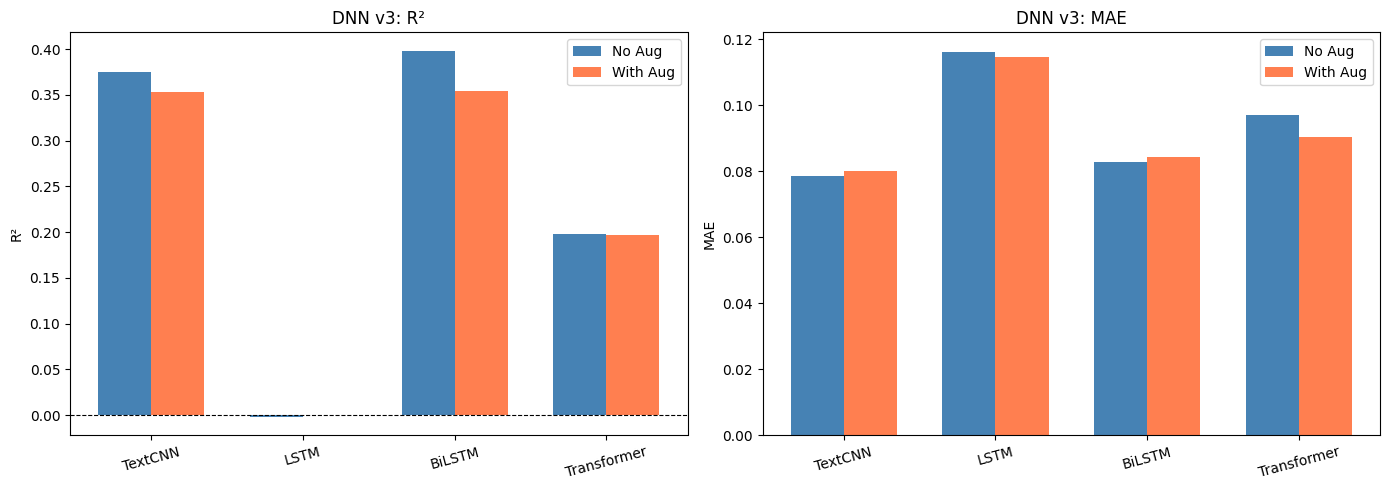

✅ Saved: /content/drive/MyDrive/ResumeProject/results/table2_chart_v3.png


In [13]:
# ========== DNN v3 CHART ==========
import matplotlib.pyplot as plt
import numpy as np

results_df = pd.read_csv(f'{RESULTS_DIR}/table2_results_v3.csv')

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
models_list = ['TextCNN', 'LSTM', 'BiLSTM', 'Transformer']
x = np.arange(len(models_list))
w = 0.35

for i, metric in enumerate(['R²', 'MAE']):
    no = [results_df[(results_df['Model']==m)&(results_df['Aug']=='No')][metric].values[0]
          if len(results_df[(results_df['Model']==m)&(results_df['Aug']=='No')])>0 else 0
          for m in models_list]
    ag = [results_df[(results_df['Model']==m)&(results_df['Aug']=='Yes')][metric].values[0]
          if len(results_df[(results_df['Model']==m)&(results_df['Aug']=='Yes')])>0 else 0
          for m in models_list]
    axes[i].bar(x-w/2, no, w, label='No Aug', color='steelblue')
    axes[i].bar(x+w/2, ag, w, label='With Aug', color='coral')
    axes[i].set_xticks(x); axes[i].set_xticklabels(models_list, rotation=15)
    axes[i].set_ylabel(metric); axes[i].set_title(f'DNN v3: {metric}')
    axes[i].legend()
    if metric == 'R²': axes[i].axhline(0, color='black', linestyle='--', linewidth=0.8)

plt.tight_layout()
plt.savefig(f'{RESULTS_DIR}/table2_chart_v3.png', dpi=150, bbox_inches='tight')
plt.show()
print(f"✅ Saved: {RESULTS_DIR}/table2_chart_v3.png")